<a href="https://colab.research.google.com/github/Santibareiro27/Facultad_programs/blob/main/RA1_LAB3/EXPERIENCIA_2/RA1_Lab3_E2_G8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratorio 3 — Transfer Learning y Adaptación de Modelos Preentrenados


## Experiencia 2: Sistema de detección de violencia en cámaras de seguridad



**Dataset:** `Violencia_Dataset` — `~1.951` videos (`~1.000` violentos, `~951` no violentos)  
**Framework:** TensorFlow / Keras  
**Grupo:** — Numero 8  
**Fecha:** — 05/2026

---


### 0. Contexto del problema


**CONTEXTO:**  
  Una empresa de seguridad opera cámaras en estaciones de transporte,
  estadios y centros comerciales. Los operadores deben vigilar docenas
  de flujos simultáneamente, la fatiga hace que eventos violentos
  breves sean frecuentemente omitidos.

  El sistema propuesto: analizar los videos automáticamente y generar
  una alerta cuando se detecta actividad violenta. El operador confirma
  o descarta la alerta antes de actuar.

**REQUERIMIENTOS DEL SISTEMA:**  
  - Clasificar video en: violencia / no violencia
  - Tasa de falsas alarmas aceptable (el operador pierde confianza
    si el sistema genera demasiados falsos positivos)
  - Latencia razonable para análisis casi en tiempo real


---



### 1. Configuración del entorno


In [2]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'  # Oculta los mensajes INFO y WARNING de C++
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import cv2
import glob
import time
import random
import pickle
import struct
import warnings
warnings.filterwarnings('ignore')


from pathlib import Path
from tqdm.auto import tqdm
from IPython.display import HTML
from base64 import b64encode

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import (EarlyStopping, ReduceLROnPlateau, ModelCheckpoint)
from tensorflow.keras import backend as K

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, roc_curve, average_precision_score, precision_recall_curve)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Parámetros globales del pipeline
IMG_SIZE     = 224     # resolución de entrada al backbone
N_FRAMES     = 16      # frames muestreados por video (justificado en Sección 3)
BATCH_SIZE   = 32
LABELS       = {0: 'No Violencia', 1: 'Violencia'}

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "figure.facecolor": "white"})

print(f"TensorFlow: {tf.__version__}")
print(f"GPU disponible: {len(tf.config.list_physical_devices('GPU')) > 0}")
print("Entorno configurado.")

TensorFlow: 2.20.0
GPU disponible: True
Entorno configurado.


In [3]:
import glob
import gdown
import zipfile

# Definir la carpeta base
base_dir = "./Violencia_Dataset"

# Comprobar si el dataset ya fue extraído
if os.path.exists(base_dir) and os.path.isdir(base_dir):
    print(f"El directorio '{base_dir}' ya existe. Saltando descarga y extracción.")
else:
    print("El dataset no se encontró. Iniciando descarga...")
    file_id = "1hv24w8GBH7zpPPJVqDx1zYoq2icsvcHT"
    zip_filename = "Violencia_Dataset.zip"

    # Descargar solo si el archivo .zip tampoco existe
    if not os.path.exists(zip_filename):
        gdown.download(f"https://drive.google.com/uc?id={file_id}", zip_filename, quiet=False)

    print("Extrayendo archivos...")
    with zipfile.ZipFile(zip_filename, "r") as z:
        z.extractall(".")
    print("Extracción completada.")

# Verificar estructura
PATHS = {
    0: f"{base_dir}/NoViolencia/",
    1: f"{base_dir}/Violencia/"
}

LABELS = {0: 'No Violencia', 1: 'Violencia'}

for label, path in PATHS.items():
    if os.path.exists(path):
        n = len(glob.glob(path + "*.mp4"))
        print(f"  Clase {label} ({LABELS[label]}): {n} videos")
    else:
        print(f"  Clase {label} ({LABELS[label]}): Directorio no encontrado.")

El dataset no se encontró. Iniciando descarga...


Downloading...
From (original): https://drive.google.com/uc?id=1hv24w8GBH7zpPPJVqDx1zYoq2icsvcHT
From (redirected): https://drive.google.com/uc?id=1hv24w8GBH7zpPPJVqDx1zYoq2icsvcHT&confirm=t&uuid=45dd2382-7faf-4502-bcde-47c82c0dafba
To: /content/Violencia_Dataset.zip
100%|██████████| 1.92G/1.92G [00:31<00:00, 61.4MB/s]


Extrayendo archivos...
Extracción completada.
  Clase 0 (No Violencia): 951 videos
  Clase 1 (Violencia): 1000 videos



---



### 2. Exploración del dataset


In [4]:
# Función para reproducir un video en el notebook
def play_video(filepath, width=480):
    """Muestra un video inline en el notebook."""
    with open(filepath, 'rb') as f:
        video_data = f.read()
    src = 'data:video/mp4;base64,' + b64encode(video_data).decode()
    return HTML(f'<video width={width} controls><source src="{src}" type="video/mp4"></video>')


# Análisis de propiedades del dataset
print("Analizando propiedades de los videos...")

stats = []
for label, path in PATHS.items():
    for video_path in glob.glob(path + "*.mp4"):
        cap = cv2.VideoCapture(video_path)
        n_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        fps      = cap.get(cv2.CAP_PROP_FPS)
        width    = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
        height   = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
        cap.release()
        stats.append({'label': label, 'n_frames': n_frames, 'fps': fps,
                       'width': width, 'height': height,
                       'duration_s': n_frames / fps if fps > 0 else 0,
                       'path': video_path})

df_stats = pd.DataFrame(stats)
print(f"\nTotal de videos: {len(df_stats)}")

Analizando propiedades de los videos...

Total de videos: 1951


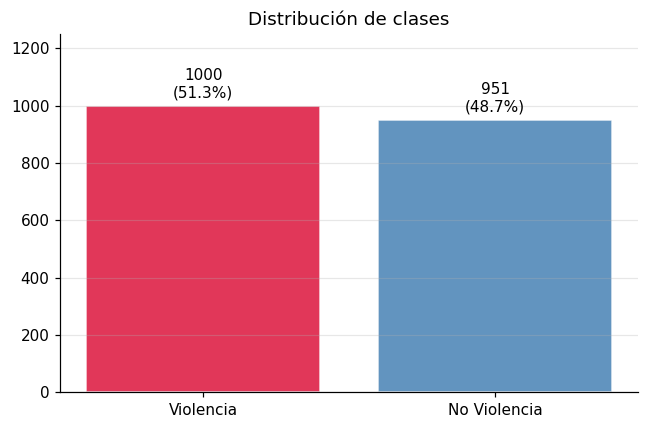

In [6]:
# Distribución de clases
fig, ax = plt.subplots(1, 1, figsize=(6, 4))
class_counts = df_stats['label'].value_counts()
ax.bar([LABELS[i] for i in class_counts.index], class_counts.values,
                color=['crimson','steelblue'], alpha=0.85, edgecolor='white')

max_y = class_counts.values.max()
ax.set_ylim(0, max_y * 1.25)

for i, v in enumerate(class_counts.values):
    ax.text(i, v + (max_y * 0.03), f"{v}\n({v/len(df_stats)*100:.1f}%)", ha='center', fontsize=10)
ax.set_title("Distribución de clases"); ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

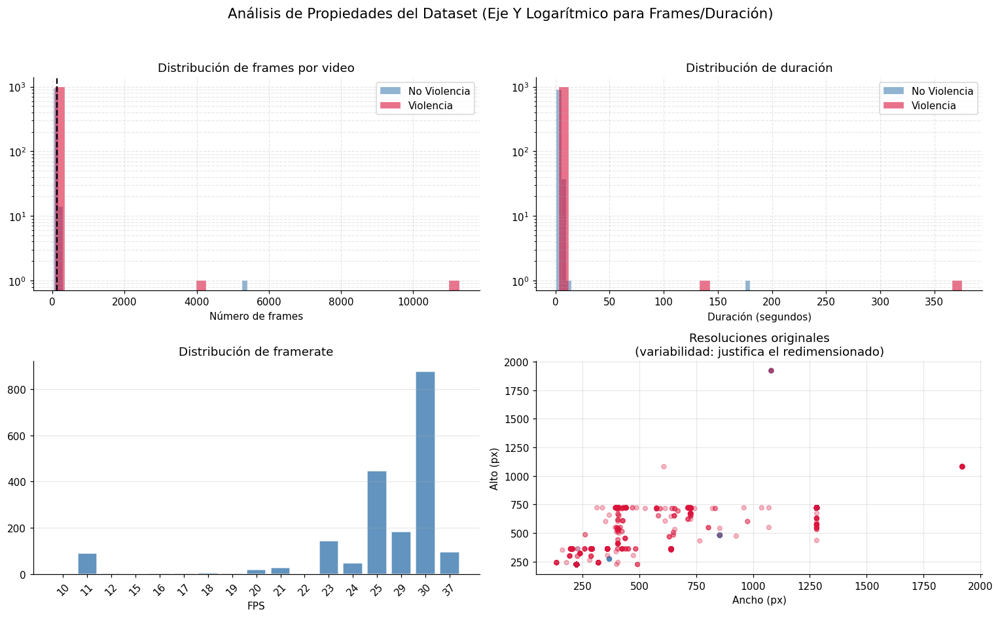


Resumen estadístico detallado:


,Mínimo,P25,Mediana,P75,P95,Máximo
n_frames,29.00,120.00,132.00,150.00,185.00,11272.00
duration_s,1.00,4.80,5.00,5.00,5.81,375.73
fps,10.50,25.00,29.47,30.00,30.01,37.00


In [11]:
# Distribución de propiedades
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# Frames por video
for label, color in [(0, 'steelblue'), (1, 'crimson')]:
    mask = df_stats['label'] == label
    axes[0, 0].hist(df_stats[mask]['n_frames'], bins=40, alpha=0.6, color=color,
                     label=LABELS[label], edgecolor='white', linewidth=0.3)
axes[0, 0].set_xlabel("Número de frames"); axes[0, 0].set_title("Distribución de frames por video")
axes[0, 0].set_yscale('log')
axes[0, 0].legend(); axes[0, 0].grid(True, alpha=0.3, which='both', linestyle='--')
axes[0, 0].axvline(df_stats['n_frames'].median(), color='black', lw=1.5,
                    linestyle='--', label=f"Mediana: {df_stats['n_frames'].median():.0f}")

# Duración en segundos
for label, color in [(0, 'steelblue'), (1, 'crimson')]:
    mask = df_stats['label'] == label
    axes[0, 1].hist(df_stats[mask]['duration_s'], bins=40, alpha=0.6, color=color,
                     label=LABELS[label], edgecolor='white', linewidth=0.3)
axes[0, 1].set_xlabel("Duración (segundos)"); axes[0, 1].set_title("Distribución de duración")
axes[0, 1].set_yscale('log')
axes[0, 1].legend(); axes[0, 1].grid(True, alpha=0.3, which='both', linestyle='--')

# FPS
# Redondeamos a números enteros para agrupar y rotamos el texto
fps_counts = df_stats['fps'].round().value_counts().sort_index()
axes[1, 0].bar(fps_counts.index.astype(int).astype(str), fps_counts.values,
                color='steelblue', alpha=0.85, edgecolor='white')
axes[1, 0].set_xlabel("FPS"); axes[1, 0].set_title("Distribución de framerate")
axes[1, 0].tick_params(axis='x', rotation=45)
axes[1, 0].grid(True, alpha=0.3, axis='y')

# Resoluciones
axes[1, 1].scatter(df_stats['width'], df_stats['height'],
                    c=[('steelblue' if l == 0 else 'crimson') for l in df_stats['label']],
                    alpha=0.3, s=20)
axes[1, 1].set_xlabel("Ancho (px)"); axes[1, 1].set_ylabel("Alto (px)")
axes[1, 1].set_title("Resoluciones originales\n(variabilidad: justifica el redimensionado)")
axes[1, 1].grid(True, alpha=0.3)

plt.suptitle("Análisis de Propiedades del Dataset (Eje Y Logarítmico para Frames/Duración)", fontsize=14, y=0.98)
plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Ajuste para evitar superposición con el suptitle
plt.show() # Forzar visualización de gráficos antes del texto

# Resumen estadístico visualmente impactante
print("\nResumen estadístico detallado:")
resumen = df_stats[['n_frames', 'duration_s', 'fps']].describe(percentiles=[.25, .5, .75, .95]).T
resumen = resumen[['min', '25%', '50%', '75%', '95%', 'max']]
resumen.columns = ['Mínimo', 'P25', 'Mediana', 'P75', 'P95', 'Máximo']

# Aplicación de estilos avanzados mediante Pandas Styler
styled_resumen = (resumen.style
                  .format("{:.2f}")
                  .set_table_styles([
                      {'selector': 'caption', 'props': [('color', '#2c3e50'), ('font-size', '16px'), ('font-weight', 'bold'), ('text-align', 'center'), ('padding-bottom', '10px')]},                     {'selector': 'th', 'props': [('background-color', '#f8f9fa'), ('color', '#2c3e50'), ('font-family', 'sans-serif'), ('text-align', 'center')]},
                      {'selector': 'td', 'props': [('text-align', 'center'), ('font-family', 'monospace')]}
                  ]))

display(styled_resumen)

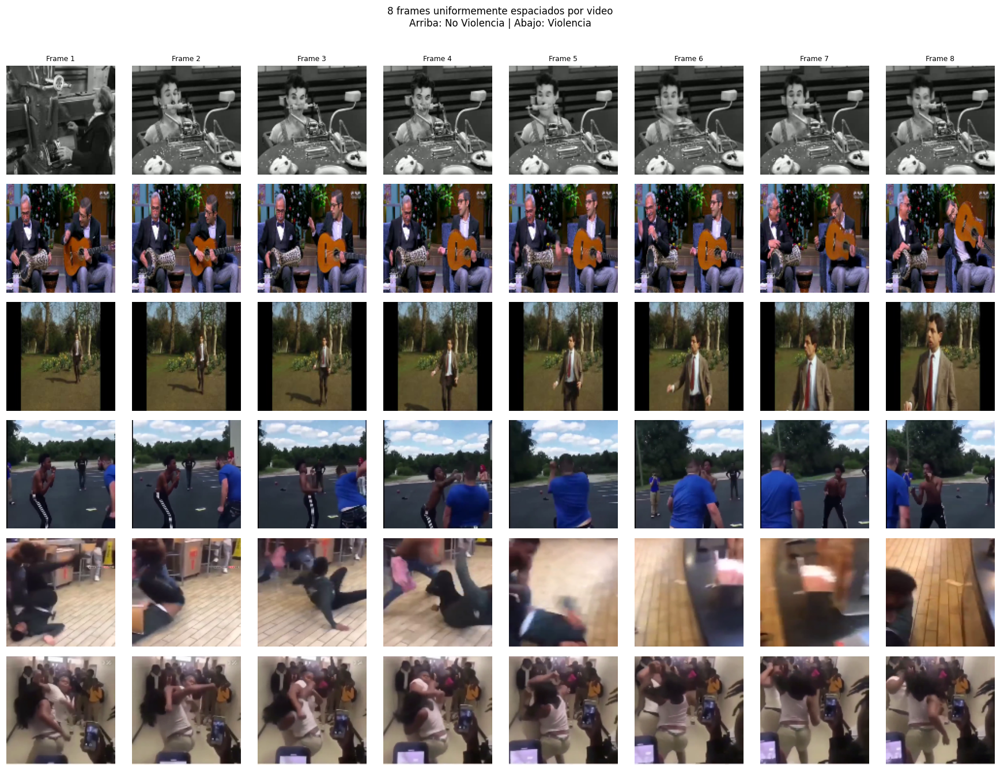

In [12]:
# Visualizar frames de ejemplo de ambas clases
def get_sample_frames(video_path, n_frames=8, size=(112, 112)):
    """Extrae n frames uniformemente espaciados de un video."""
    cap = cv2.VideoCapture(video_path)
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    indices = np.linspace(0, total - 1, n_frames, dtype=int)
    frames = []
    for idx in indices:
        cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
        ret, frame = cap.read()
        if ret:
            frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            frame = cv2.resize(frame, size)
            frames.append(frame)
    cap.release()
    return frames

n_ejemplos = 3
fig, axes = plt.subplots(2 * n_ejemplos, 8, figsize=(16, 4 * n_ejemplos))

for row, label in enumerate([0, 1]):
    sample_videos = df_stats[df_stats['label'] == label]['path'].sample(n_ejemplos, random_state=SEED).values
    for i, video_path in enumerate(sample_videos):
        frames = get_sample_frames(video_path, n_frames=8)
        for j, frame in enumerate(frames):
            ax = axes[row * n_ejemplos + i, j]
            ax.imshow(frame)
            ax.axis('off')
            if j == 0:
                ax.set_ylabel(f"{LABELS[label]}\n{Path(video_path).stem}",
                               fontsize=8, rotation=0, labelpad=70, va='center')
            if row == 0 and i == 0:
                ax.set_title(f"Frame {j+1}", fontsize=8)

plt.suptitle("8 frames uniformemente espaciados por video\n"
             "Arriba: No Violencia | Abajo: Violencia", fontsize=11, y=1.01)
plt.tight_layout()
plt.show()


---



### 3. Estrategia de muestreo temporal


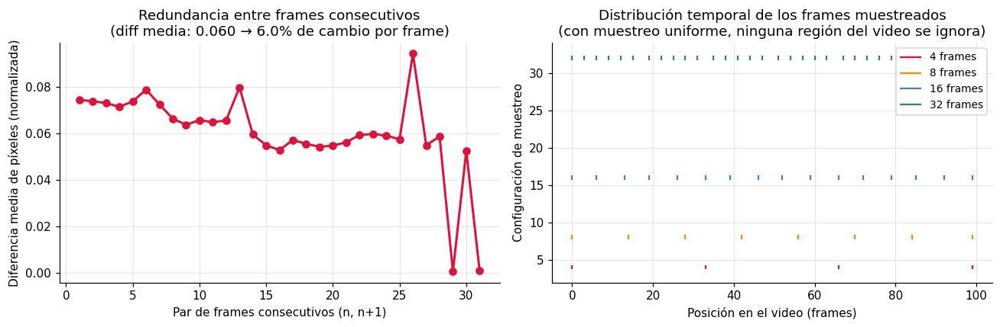


Conclusion: la diferencia media entre frames consecutivos es 6.0%.
Muestrear 1 de cada 8-16 frames preserva la información relevante
y reduce el costo de preprocesamiento en 84%.


In [13]:
# Cuantificar la redundancia entre frames consecutivos
video_ejemplo = df_stats[df_stats['label'] == 1]['path'].iloc[0]

cap = cv2.VideoCapture(video_ejemplo)
frames_muestra = []
for _ in range(min(32, int(cap.get(cv2.CAP_PROP_FRAME_COUNT)))):
    ret, frame = cap.read()
    if ret:
        frame = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        frames_muestra.append(frame.flatten().astype(float))
cap.release()

# Diferencia media entre frames consecutivos
diffs = [np.mean(np.abs(frames_muestra[i+1] - frames_muestra[i]) / 255)
         for i in range(len(frames_muestra) - 1)]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(range(1, len(diffs)+1), diffs, 'o-', color='crimson', lw=2, ms=6)
axes[0].set_xlabel("Par de frames consecutivos (n, n+1)")
axes[0].set_ylabel("Diferencia media de píxeles (normalizada)")
axes[0].set_title(f"Redundancia entre frames consecutivos\n"
                   f"(diff media: {np.mean(diffs):.3f} → {np.mean(diffs)*100:.1f}% de cambio por frame)")
axes[0].grid(True, alpha=0.3)

# Visualizar cuánta información "nueva" hay al samplear a distintas frecuencias
n_total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT)) if cap.isOpened() else 100
for n_frames, color, ls in [(4, 'crimson', '-'), (8, 'darkorange', '--'),
                              (16, 'steelblue', '-'), (32, 'seagreen', ':')]:
    indices = np.linspace(0, n_total - 1, n_frames, dtype=int)
    axes[1].eventplot(indices, lineoffsets=[n_frames], linelengths=0.6,
                       color=color, label=f"{n_frames} frames")
axes[1].set_xlabel("Posición en el video (frames)")
axes[1].set_ylabel("Configuración de muestreo")
axes[1].set_title("Distribución temporal de los frames muestreados\n"
                   "(con muestreo uniforme, ninguna región del video se ignora)")
axes[1].legend(fontsize=9)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\nConclusion: la diferencia media entre frames consecutivos es {np.mean(diffs)*100:.1f}%.")
print("Muestrear 1 de cada 8-16 frames preserva la información relevante")
print(f"y reduce el costo de preprocesamiento en {(1 - 16/n_total)*100:.0f}%.")


---



### 4. Selección del backbone


In [23]:
import time
import numpy as np
import tensorflow as tf

print("COMPARACIÓN DE ENFOQUES: \n")

def medir_embedding(nombre_modelo, model_builder, sample_input):
    """Mide la dimensión del embedding y el tiempo de inferencia por frame."""
    model = model_builder()
    t0 = time.time()
    for _ in range(10):
        _ = model(sample_input, training=False)
    t_ms = (time.time() - t0) / 10 * 1000

    output_shape = model.output_shape
    embed_dim    = np.prod(output_shape[1:])
    return embed_dim, t_ms, output_shape

muestra_input = tf.random.normal((1, 224, 224, 3))

# Comparar distintos backbones con GAP
backbones_config = {
    'MobileNetV2 + GAP':          tf.keras.applications.MobileNetV2,
    'MobileNetV3Large + GAP':     tf.keras.applications.MobileNetV3Large,
    'EfficientNetB0 + GAP':       tf.keras.applications.EfficientNetB0,
    'EfficientNetV2S + GAP':      tf.keras.applications.EfficientNetV2S,
    'ResNet50V2 + GAP':           tf.keras.applications.ResNet50V2,
}

resultados_backbones = {}

# Diseño de tabla ASCII limpia (Blanco y Negro)
print("┌" + "─"*25 + "┬" + "─"*13 + "┬" + "─"*10 + "┬" + "─"*16 + "┬" + "─"*12 + "┬" + "─"*10 + "┐")
print(f"│ {'Backbone':<23} │ {'Parámetros':>11} │ {'Emb. Dim':>8} │ {'MB/video (16f)':>14} │ {'GB (1951v)':>10} │ {'ms/frame':>8} │")
print("├" + "─"*25 + "┼" + "─"*13 + "┼" + "─"*10 + "┼" + "─"*16 + "┼" + "─"*12 + "┼" + "─"*10 + "┤")

for nombre, app_class in list(backbones_config.items()):
    try:
        base = app_class(include_top=False, weights='imagenet', input_shape=(224, 224, 3))
        model_gap = tf.keras.Sequential([base, tf.keras.layers.GlobalAveragePooling2D()])

        embed_dim = model_gap.output_shape[-1]
        params    = base.count_params()

        # Warm-up de la GPU para que el tiempo sea real
        _ = model_gap(muestra_input, training=False)

        t0 = time.time()
        for _ in range(5):
            _ = model_gap(muestra_input, training=False)
        t_ms = (time.time() - t0) / 5 * 1000

        mb_por_video = 16 * embed_dim * 4 / 1e6
        gb_total     = 1951 * 16 * embed_dim * 4 / 1e9

        resultados_backbones[nombre] = {
            'embed_dim': embed_dim, 'mb_video': mb_por_video,
            'gb_total': gb_total, 'ms': t_ms, 'params': params
        }

        # La coma en params (:,) separa automáticamente los miles para que sea más legible
        print(f"│ {nombre:<23} │ {params:>11,} │ {embed_dim:>8} │ {mb_por_video:>14.2f} │ {gb_total:>10.2f} │ {t_ms:>8.0f} │")

    except Exception as e:
        print(f"│ {nombre:<23} │ Error: {str(e):<68} │")

print("└" + "─"*25 + "┴" + "─"*13 + "┴" + "─"*10 + "┴" + "─"*16 + "┴" + "─"*12 + "┴" + "─"*10 + "┘")

COMPARACIÓN DE ENFOQUES: 

┌─────────────────────────┬─────────────┬──────────┬────────────────┬────────────┬──────────┐
│ Backbone                │  Parámetros │ Emb. Dim │ MB/video (16f) │ GB (1951v) │ ms/frame │
├─────────────────────────┼─────────────┼──────────┼────────────────┼────────────┼──────────┤
│ MobileNetV2 + GAP       │   2,257,984 │     1280 │           0.08 │       0.16 │      214 │
│ MobileNetV3Large + GAP  │   2,996,352 │      960 │           0.06 │       0.12 │      183 │
│ EfficientNetB0 + GAP    │   4,049,571 │     1280 │           0.08 │       0.16 │      284 │
│ EfficientNetV2S + GAP   │  20,331,360 │     1280 │           0.08 │       0.16 │      666 │
│ ResNet50V2 + GAP        │  23,564,800 │     2048 │           0.13 │       0.26 │      199 │
└─────────────────────────┴─────────────┴──────────┴────────────────┴────────────┴──────────┘


SELECCIÓN: `MobileNetV3Large + GAP`  
  - Embedding `960D`: `120 MB` para todo el dataset → mejor optimizacion de recursos
  - Accuracy mayor que su predecesor y ligeramente menor que EfficientNetB0 en ImageNet, con una cantidad de parametros similar
  - Mayor velocidad de procesamiento de frames que EfficientNetB0

In [ ]:
# Construir el extractor de embeddings final
print("Construyendo extractor de embeddings (MobileNetV3Large + GAP)...")

from keras.applications.mobilenet_v3 import preprocess_input as mobilenet_preprocess

backbone = tf.keras.applications.MobileNetV3Large(
    include_top=False,
    weights='imagenet',
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)
backbone.trainable = False

extractor = tf.keras.Sequential([
    tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name='input_frames'),
    tf.keras.layers.Lambda(mobilenet_preprocess, name='preprocess_input'),
    backbone,
    tf.keras.layers.GlobalAveragePooling2D()
], name='feature_extractor')

EMBED_DIM = extractor.output_shape[-1]
print(f"Dimensión del embedding: {EMBED_DIM}")
print(f"Parámetros del backbone: {backbone.count_params():,}")
print()

# Estimado de memoria para el dataset completo
n_videos_total = len(df_stats)
mb_total = n_videos_total * N_FRAMES * EMBED_DIM * 4 / 1e6
print(f"Estimado de memoria para todos los embeddings:")
print(f"  {n_videos_total} videos × {N_FRAMES} frames × {EMBED_DIM} dims × 4 bytes")
print(f"  = {mb_total:.0f} MB → manejable en RAM")

Construyendo extractor de embeddings (MobileNetV3Large + GAP)...
Dimensión del embedding: 960
Parámetros del backbone: 2,996,352

Estimado de memoria para todos los embeddings:
  1951 videos × 16 frames × 960 dims × 4 bytes
  = 120 MB → manejable en RAM



---



### 5. Preprocesamiento offline — generación de TFRecords


In [ ]:
def sample_frames(video_path: str, n_frames: int = N_FRAMES,
                   size: int = IMG_SIZE) -> np.ndarray:

    cap    = cv2.VideoCapture(video_path)
    total  = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    if total < n_frames:
        indices = list(range(total)) + [total - 1] * (n_frames - total)
    else:
        indices = np.linspace(0, total - 1, n_frames, dtype=int)

    frames = []
    for idx in indices:
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx))
        ret, frame = cap.read()
        if ret:
            frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            frame = cv2.resize(frame, (size, size))
            frames.append(frame)
        else:
            frames.append(frames[-1] if frames else np.zeros((size, size, 3), dtype=np.uint8))

    cap.release()
    arr = np.array(frames, dtype=np.float32)
    # MobileNetV3 incluye el reescalado internamente: preprocess_input es no-op,
    # pero se mantiene por claridad y portabilidad a otros backbones.
    arr = mobilenet_preprocess(arr)
    return arr


def extract_video_embeddings(video_path: str) -> np.ndarray:
    """
    Pipeline completo: video -> frames (limpios) -> preprocesamiento -> embeddings.
    """
    frames_arr = sample_frames(video_path, n_frames=N_FRAMES)
    # Extraemos los embeddings usando la GPU
    embeddings = extractor.predict(frames_arr, batch_size=BATCH_SIZE, verbose=0)
    return embeddings.astype(np.float32)


# Prueba con un video de ejemplo
video_test = df_stats.iloc[0]['path']
emb_test   = extract_video_embeddings(video_test)
print(f"Shape de embeddings por video: {emb_test.shape}")
print(f"  -> {N_FRAMES} frames x {EMBED_DIM} dimensiones")
print(f"  -> {emb_test.nbytes / 1024:.1f} KB por video")


Shape de embeddings por video: (16, 960)
  -> 16 frames x 960 dimensiones
  -> 60.0 KB por video


In [ ]:
# Funciones TFRecord
def video_to_tfrecord_example(embeddings: np.ndarray, label: int) -> tf.train.Example:
    """
    Serializa los embeddings de un video y su etiqueta como tf.train.Example.
    """
    emb_bytes = embeddings.tobytes()
    feature = {
        'embeddings': tf.train.Feature(
            bytes_list=tf.train.BytesList(value=[emb_bytes])),
        'label': tf.train.Feature(
            int64_list=tf.train.Int64List(value=[label])),
        'n_frames': tf.train.Feature(
            int64_list=tf.train.Int64List(value=[embeddings.shape[0]])),
        'embed_dim': tf.train.Feature(
            int64_list=tf.train.Int64List(value=[embeddings.shape[1]])),
    }
    return tf.train.Example(features=tf.train.Features(feature=feature))


def parse_tfrecord(serialized_example):
    """
    Función de parseo para tf.data.Dataset.
    Reconstruye el tensor de embeddings desde el binario serializado
    USANDO FORMAS ESTÁTICAS para compatibilidad con Keras 3.
    """
    feature_description = {
        'embeddings': tf.io.FixedLenFeature([], tf.string),
        'label':      tf.io.FixedLenFeature([], tf.int64),
        # Ya no necesitamos leer n_frames y embed_dim para el reshape
        'n_frames':   tf.io.FixedLenFeature([], tf.int64),
        'embed_dim':  tf.io.FixedLenFeature([], tf.int64),
    }
    parsed = tf.io.parse_single_example(serialized_example, feature_description)
    embeddings = tf.io.decode_raw(parsed['embeddings'], tf.float32)

    # --- CAMBIO CRÍTICO ACÁ ---
    # En lugar de usar parsed['n_frames'] y parsed['embed_dim'], usamos las constantes
    embeddings = tf.reshape(embeddings, [N_FRAMES, EMBED_DIM])
    # --------------------------

    label = tf.cast(parsed['label'], tf.int32)
    return embeddings, label


# División del dataset (estratificada)
all_videos = [(label, row['path']) for _, row in df_stats.iterrows()
               for label in [row['label']]]

# Split estratificado 70/15/15
video_paths_all = [p for _, p in all_videos]
labels_all      = [l for l, _ in all_videos]

idx_train, idx_tmp = train_test_split(
    range(len(video_paths_all)), test_size=0.30, stratify=labels_all, random_state=SEED)
labels_tmp = [labels_all[i] for i in idx_tmp]
idx_val, idx_test = train_test_split(
    idx_tmp, test_size=0.50, stratify=labels_tmp, random_state=SEED)

splits = {
    'train': [(labels_all[i], video_paths_all[i]) for i in idx_train],
    'val':   [(labels_all[i], video_paths_all[i]) for i in idx_val],
    'test':  [(labels_all[i], video_paths_all[i]) for i in idx_test],
}

print("División del dataset:")
for split, videos in splits.items():
    n0 = sum(1 for l, _ in videos if l == 0)
    n1 = sum(1 for l, _ in videos if l == 1)
    print(f"  {split:<6}: {len(videos):>4} videos  "
          f"(NoViolencia: {n0}  Violencia: {n1})")

División del dataset:
  train : 1365 videos  (NoViolencia: 665  Violencia: 700)
  val   :  293 videos  (NoViolencia: 143  Violencia: 150)
  test  :  293 videos  (NoViolencia: 143  Violencia: 150)


In [ ]:
# Generar TFRecords para cada split
TFRECORD_DIR = Path("tfrecords")
TFRECORD_DIR.mkdir(exist_ok=True)

def generar_tfrecord(split_name: str, video_list: list, overwrite: bool = False):
    """
    Genera el archivo TFRecord para un split.
    Mide y reporta el tiempo y tamaño.
    """
    output_path = TFRECORD_DIR / f"{split_name}.tfrecord"

    if output_path.exists() and not overwrite:
        size_mb = output_path.stat().st_size / 1e6
        print(f"  {split_name}: ya existe ({size_mb:.1f} MB) — saltando")
        return output_path

    t0     = time.time()
    n_ok   = 0
    n_err  = 0

    with tf.io.TFRecordWriter(str(output_path)) as writer:
        for label, video_path in tqdm(video_list, desc=f"Generando {split_name}"):
            try:
                embeddings = extract_video_embeddings(video_path)
                example    = video_to_tfrecord_example(embeddings, label)
                writer.write(example.SerializeToString())
                n_ok += 1
            except Exception as e:
                n_err += 1

    elapsed  = time.time() - t0
    size_mb  = output_path.stat().st_size / 1e6
    ms_video = elapsed / n_ok * 1000 if n_ok > 0 else 0

    print(f"  {split_name}: {n_ok} videos ok, {n_err} errores | "
          f"{size_mb:.1f} MB | {elapsed:.0f}s | {ms_video:.0f}ms/video")
    return output_path


print("Generando TFRecords (preprocesamiento offline)...")
print("Este paso se ejecuta UNA VEZ y los archivos se reutilizan.\n")
t_preproc_start = time.time()

for split_name, video_list in splits.items():
    generar_tfrecord(split_name, video_list)

t_preproc_total = time.time() - t_preproc_start
print(f"\nTiempo total de preprocesamiento: {t_preproc_total:.0f}s ({t_preproc_total/60:.1f} min)")
print()

# Verificar tamaños
for split_name in ['train', 'val', 'test']:
    path = TFRECORD_DIR / f"{split_name}.tfrecord"
    size = path.stat().st_size / 1e6
    print(f"  {split_name}.tfrecord: {size:.1f} MB")

print()
print(f"Total embeddings: {sum((TFRECORD_DIR / f'{s}.tfrecord').stat().st_size for s in ['train','val','test']) / 1e6:.0f} MB")

Generando TFRecords (preprocesamiento offline)...
Este paso se ejecuta UNA VEZ y los archivos se reutilizan.



Generando train:   4%|▍         | 52/1365 [00:15<17:25,  1.26it/s][h264 @ 0x9d879940] mb_type 104 in P slice too large at 98 31
[h264 @ 0x9d879940] error while decoding MB 98 31
[h264 @ 0x9d8fc140] mb_type 104 in P slice too large at 98 31
[h264 @ 0x9d8fc140] error while decoding MB 98 31
[h264 @ 0x9d8fc140] mb_type 104 in P slice too large at 98 31
[h264 @ 0x9d8fc140] error while decoding MB 98 31
[h264 @ 0x9d8fc140] mb_type 104 in P slice too large at 98 31
[h264 @ 0x9d8fc140] error while decoding MB 98 31
Generando train: 100%|██████████| 1365/1365 [07:59<00:00,  2.85it/s]


  train: 1365 videos ok, 0 errores | 84.0 MB | 479s | 351ms/video


Generando val: 100%|██████████| 293/293 [01:28<00:00,  3.30it/s]


  val: 293 videos ok, 0 errores | 18.0 MB | 89s | 303ms/video


Generando test: 100%|██████████| 293/293 [01:27<00:00,  3.33it/s]

  test: 293 videos ok, 0 errores | 18.0 MB | 88s | 300ms/video

Tiempo total de preprocesamiento: 656s (10.9 min)

  train.tfrecord: 84.0 MB
  val.tfrecord: 18.0 MB
  test.tfrecord: 18.0 MB

Total embeddings: 120 MB


In [ ]:
NOISE_STD_FRAC  = 0.5   # ruido gaussiano ~10% de la variabilidad propia del embedding
FRAME_DROP_RATE = 0.10   # probabilidad de enmascarar (poner a cero) cada frame

def augment_embeddings(embeddings, label):
    """Aumentacion temporal/espacial sobre la secuencia de embeddings (solo train)."""
    # 1) Ruido gaussiano escalado a la magnitud del propio embedding
    emb_std = tf.math.reduce_std(embeddings) + 1e-6
    noise   = tf.random.normal(tf.shape(embeddings), stddev=NOISE_STD_FRAC * emb_std)
    embeddings = embeddings + noise

    # 2) Frame dropout temporal: enmascara frames completos a cero.
    #    Simula la ausencia de la "accion pico" y evita depender de un frame puntual.
    keep = tf.cast(
        tf.random.uniform([tf.shape(embeddings)[0], 1]) >= FRAME_DROP_RATE,
        embeddings.dtype)
    embeddings = embeddings * keep
    return embeddings, label


def build_dataset(split_name: str, batch_size: int = BATCH_SIZE,
                   shuffle: bool = True, augment: bool = False) -> tf.data.Dataset:
    """
    Construye un tf.data.Dataset desde el TFRecord correspondiente.
    Si augment=True (solo train), aplica aumentacion por epoca sobre los embeddings.
    """
    path = str(TFRECORD_DIR / f"{split_name}.tfrecord")
    ds = tf.data.TFRecordDataset(path, compression_type='')
    ds = ds.map(parse_tfrecord, num_parallel_calls=tf.data.AUTOTUNE)
    if augment:
        ds = ds.map(augment_embeddings, num_parallel_calls=tf.data.AUTOTUNE)
    if shuffle:
        ds = ds.shuffle(buffer_size=512, seed=SEED)
    ds = ds.batch(batch_size)
    ds = ds.prefetch(tf.data.AUTOTUNE)
    return ds


ds_train = build_dataset('train', shuffle=True,  augment=True)   # aumentado
ds_val   = build_dataset('val',   shuffle=False, augment=False)  # limpio
ds_test  = build_dataset('test',  shuffle=False, augment=False)  # limpio

# Verificar shape del primer batch
for emb_batch, lbl_batch in ds_train.take(1):
    print(f"Shape del batch de entrenamiento:")
    print(f"  Embeddings: {emb_batch.shape}  (batch x frames x embed_dim)")
    print(f"  Etiquetas:  {lbl_batch.shape}")
    print(f"  Distribucion en batch: {lbl_batch.numpy().tolist()[:10]}...")


Shape del batch de entrenamiento:
  Embeddings: (32, 16, 960)  (batch x frames x embed_dim)
  Etiquetas:  (32,)
  Distribucion en batch: [1, 1, 0, 1, 0, 1, 1, 1, 0, 1]...



---



### 6. Arquitecturas temporales


In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

# Aseguramos usar las variables estáticas que definimos arriba
INPUT_SHAPE = (N_FRAMES, EMBED_DIM)

# ─────────────────────────────────────────────────────────────────
# Pooling temporal
# ─────────────────────────────────────────────────────────────────

def build_mean_pooling(input_shape=INPUT_SHAPE):
    inputs = keras.Input(shape=input_shape, name='input')
    x = layers.GlobalAveragePooling1D(name='temporal_avg')(inputs)
    x = layers.Dense(256, activation='relu', kernel_initializer='he_normal')(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(64, activation='relu')(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(1, activation='sigmoid', name='output')(x)
    m = keras.Model(inputs, out, name='mean_pooling')
    m.compile(optimizer=keras.optimizers.Adam(1e-4),
               loss='binary_crossentropy', metrics=['accuracy'])
    return m

# ─────────────────────────────────────────────────────────────────
# LSTM
# ─────────────────────────────────────────────────────────────────

def build_lstm(input_shape=INPUT_SHAPE, units=128):
    inputs = keras.Input(shape=input_shape, name='input')
    x = layers.Dense(256, activation='relu', name='projection')(inputs)
    x = layers.Bidirectional(
        layers.LSTM(units, return_sequences=False, dropout=0.2, recurrent_dropout=0.1),
        name='bilstm'
    )(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(64, activation='relu')(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(1, activation='sigmoid', name='output')(x)
    m = keras.Model(inputs, out, name='bilstm')
    m.compile(optimizer=keras.optimizers.Adam(1e-4),
               loss='binary_crossentropy', metrics=['accuracy'])
    return m

# ─────────────────────────────────────────────────────────────────
# Temporal Self-Attention
# ─────────────────────────────────────────────────────────────────
import tensorflow as tf

def build_temporal_attention(input_shape=INPUT_SHAPE, num_heads=4):
    inputs = keras.Input(shape=input_shape, name='input')
    x = layers.Dense(256, activation='relu', name='projection')(inputs)
    positions = tf.range(start=0, limit=input_shape[0], delta=1)
    pos_emb   = layers.Embedding(input_shape[0], 256, name='pos_embedding')(positions)
    x         = x + pos_emb
    attn_out = layers.MultiHeadAttention(
        num_heads=num_heads, key_dim=256 // num_heads, dropout=0.1, name='temporal_attention'
    )(x, x)
    x = layers.Add()([x, attn_out])
    x = layers.LayerNormalization(name='ln1')(x)
    ff = layers.Dense(512, activation='relu')(x)
    ff = layers.Dropout(0.1)(ff)
    ff = layers.Dense(256)(ff)
    x  = layers.Add()([x, ff])
    x  = layers.LayerNormalization(name='ln2')(x)
    x   = layers.GlobalAveragePooling1D(name='temporal_gap')(x)
    x   = layers.Dense(128, activation='relu')(x)
    x   = layers.Dropout(0.4)(x)
    out = layers.Dense(1, activation='sigmoid', name='output')(x)
    m   = keras.Model(inputs, out, name='temporal_attention')
    m.compile(optimizer=keras.optimizers.Adam(1e-4),
               loss='binary_crossentropy', metrics=['accuracy'])
    return m

# Resumen de arquitecturas
modelos_config = {
    'Mean Pooling':          build_mean_pooling,
    'BiLSTM':                build_lstm,
    'Temporal Attention':    build_temporal_attention,
}

print("Arquitecturas a comparar:")
print(f"\n  {'Nombre':<26}  {'Parámetros':>12}  {'Procesa orden':>15}  {'Complejidad'}")
print("  " + "─"*68)

clasif_orden = {
    'Mean Pooling': 'No', 'Max Pooling': 'No', 'Conv1D': 'Local',
    'BiGRU': 'Sí (sec.)', 'BiLSTM': 'Sí (sec.)',
    'Temporal Attention': 'Sí (global)', 'LSTM + Attention': 'Sí (ambos)'
}

for nombre, builder in modelos_config.items():
    m = builder()
    print(f"  {nombre:<26}  {m.count_params():>12,}  {clasif_orden[nombre]:>15}  OK")
    del m

Arquitecturas a comparar:

  Nombre                        Parámetros    Procesa orden  Complejidad
  ────────────────────────────────────────────────────────────────────
  Mean Pooling                     262,529               No  OK
  BiLSTM                           681,473        Sí (sec.)  OK
  Temporal Attention               806,145      Sí (global)  OK



---



### 7. Entrenamiento y comparación de cabezas temporales


In [ ]:
def entrenar_modelo(nombre: str, builder_fn, ds_train, ds_val,
                     epochs: int = 30) -> dict:
    """
    Entrena una cabeza temporal y retorna métricas y history.
    """
    # LIMPIEZA DE MEMORIA: Fundamental para evitar el error Out Of Memory (OOM)
    K.clear_session()

    tf.random.set_seed(SEED)
    modelo = builder_fn()

    cb = [
        EarlyStopping(monitor='val_accuracy', patience=8, mode='max',
                      restore_best_weights=True, verbose=0),
        ReduceLROnPlateau(monitor='val_accuracy', factor=0.5, patience=4,
                          mode='max', min_lr=1e-6, verbose=0),
        ModelCheckpoint(f'checkpoints/{nombre.replace(" ", "_")}_best.keras',
                        monitor='val_accuracy', mode='max',
                        save_best_only=True, verbose=0)
    ]

    os.makedirs('checkpoints', exist_ok=True)

    t0 = time.time()
    history = modelo.fit(
        ds_train, validation_data=ds_val,
        epochs=epochs, callbacks=cb, verbose=0
    )
    elapsed = time.time() - t0

    val_acc_best = max(history.history['val_accuracy'])
    n_epochs_run = len(history.history['loss'])

    return {
        'modelo': modelo,
        'history': history.history,
        'val_acc': val_acc_best,
        'params': modelo.count_params(),
        'tiempo': elapsed,
        'n_epochs': n_epochs_run,
    }

# Entrenar todos los modelos
print("Entrenando todas las cabezas temporales...")
print("(Cada modelo tomará un par de minutos dependiendo de la carga en tu GPU)\n")

resultados = {}
for nombre, builder_fn in modelos_config.items():
    print(f"  Entrenando {nombre}...", end=' ', flush=True)
    try:
        r = entrenar_modelo(nombre, builder_fn, ds_train, ds_val)
        resultados[nombre] = r
        print(f"val_acc={r['val_acc']:.4f}  t={r['tiempo']:.0f}s  ep={r['n_epochs']}")
    except Exception as e:
        print(f"ERROR: {e}")

Entrenando todas las cabezas temporales...
(Cada modelo tomará un par de minutos dependiendo de la carga en tu GPU)

  Entrenando Mean Pooling... val_acc=0.9488  t=10s  ep=30
  Entrenando BiLSTM... val_acc=0.9727  t=48s  ep=26
  Entrenando Temporal Attention... val_acc=0.9727  t=20s  ep=28


In [ ]:
# Tabla comparativa de resultados
print("\n" + "═"*80)
print("COMPARACIÓN DE CABEZAS TEMPORALES")
print("═"*80)

print(f"\n  {'Arquitectura':<26}  {'Val Acc':>9}  {'Params':>10}  "
      f"{'Épocas':>7}  {'Tiempo':>8}  {'Orden?':>12}")
print("  " + "─"*78)

for nombre, r in sorted(resultados.items(), key=lambda x: -x[1]['val_acc']):
    orden = clasif_orden[nombre]
    mejor = " ← MEJOR" if r['val_acc'] == max(v['val_acc'] for v in resultados.values()) else ""
    print(f"  {nombre:<26}  {r['val_acc']:>9.4f}  {r['params']:>10,}  "
          f"{r['n_epochs']:>7}  {r['tiempo']:>6.0f}s  {orden:>12}{mejor}")



════════════════════════════════════════════════════════════════════════════════
COMPARACIÓN DE CABEZAS TEMPORALES
════════════════════════════════════════════════════════════════════════════════

  Arquitectura                  Val Acc      Params   Épocas    Tiempo        Orden?
  ──────────────────────────────────────────────────────────────────────────────
  BiLSTM                         0.9727     681,473       26      48s     Sí (sec.) ← MEJOR
  Temporal Attention             0.9727     806,145       28      20s   Sí (global) ← MEJOR
  Mean Pooling                   0.9488     262,529       30      10s            No


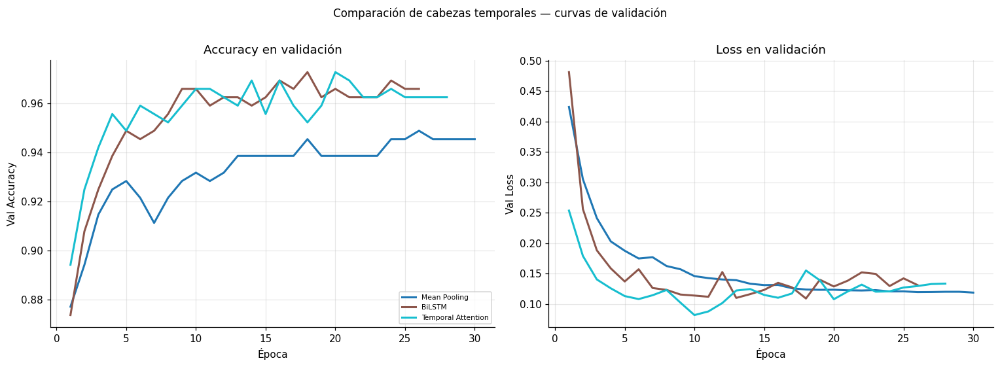

In [ ]:
# Curvas de entrenamiento comparadas
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colores = plt.cm.tab10(np.linspace(0, 1, len(resultados)))

for (nombre, r), color in zip(resultados.items(), colores):
    ep = range(1, len(r['history']['val_accuracy']) + 1)
    axes[0].plot(ep, r['history']['val_accuracy'],
                  color=color, lw=2, label=nombre)
    axes[1].plot(ep, r['history']['val_loss'],
                  color=color, lw=2, label=nombre)

for ax, yl, tl in [
    (axes[0], 'Val Accuracy', 'Accuracy en validación'),
    (axes[1], 'Val Loss',     'Loss en validación'),
]:
    ax.set_xlabel('Época'); ax.set_ylabel(yl)
    ax.set_title(tl); ax.grid(True, alpha=0.3)
axes[0].legend(fontsize=7, loc='lower right')

plt.suptitle("Comparación de cabezas temporales — curvas de validación",
             fontsize=11, y=1.01)
plt.tight_layout()
plt.show()


---

### 8. Evaluación del modelo final sobre test set


In [ ]:
# Seleccionar el mejor modelo por val_accuracy
mejor_nombre = max(resultados, key=lambda k: resultados[k]['val_acc'])
mejor_modelo = resultados[mejor_nombre]['modelo']

print(f"Modelo seleccionado: {mejor_nombre}")
print(f"Val accuracy: {resultados[mejor_nombre]['val_acc']:.4f}")
print()

# --- Scores de VALIDACIÓN (para calibrar el umbral en la celda 45) ---
y_val_true, y_val_scores = [], []
for emb_b, lbl_b in ds_val:
    p = mejor_modelo(emb_b, training=False).numpy().flatten()
    y_val_scores.extend(p); y_val_true.extend(lbl_b.numpy())
y_val_true   = np.array(y_val_true)
y_val_scores = np.array(y_val_scores)

# --- Scores de TEST (para la evaluación final) ---
y_true, y_scores = [], []
for emb_batch, lbl_batch in ds_test:
    preds = mejor_modelo(emb_batch, training=False).numpy().flatten()
    y_scores.extend(preds); y_true.extend(lbl_batch.numpy())
y_true   = np.array(y_true)
y_scores = np.array(y_scores)
y_pred   = (y_scores > 0.5).astype(int)

print("Reporte de clasificación (umbral 0.5, referencia):\n")
print(classification_report(y_true, y_pred, target_names=list(LABELS.values())))

Modelo seleccionado: BiLSTM
Val accuracy: 0.9727

Reporte de clasificación (umbral 0.5, referencia):

              precision    recall  f1-score   support

No Violencia       0.97      0.97      0.97       143
   Violencia       0.97      0.97      0.97       150

    accuracy                           0.97       293
   macro avg       0.97      0.97      0.97       293
weighted avg       0.97      0.97      0.97       293



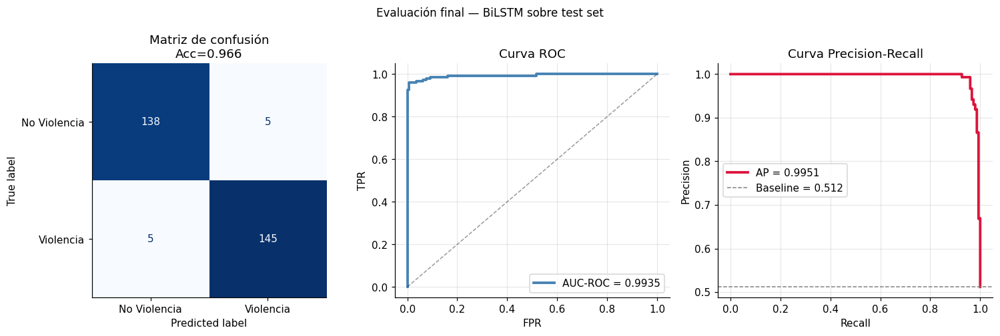

In [ ]:
# Análisis completo de métricas
auc_roc = roc_auc_score(y_true, y_scores)
auc_pr  = average_precision_score(y_true, y_scores)
acc     = accuracy_score(y_true, y_pred)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))

# Matriz de confusión
cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(cm, display_labels=list(LABELS.values())).plot(
    ax=axes[0], colorbar=False, cmap='Blues', values_format='d')
axes[0].set_title(f"Matriz de confusión\nAcc={acc:.3f}")

# Curva ROC
fpr, tpr, _ = roc_curve(y_true, y_scores)
axes[1].plot(fpr, tpr, 'steelblue', lw=2.5, label=f'AUC-ROC = {auc_roc:.4f}')
axes[1].plot([0, 1], [0, 1], 'k--', lw=1, alpha=0.4)
axes[1].set_xlabel("FPR"); axes[1].set_ylabel("TPR")
axes[1].set_title("Curva ROC"); axes[1].legend(); axes[1].grid(True, alpha=0.3)

# Curva Precision-Recall
prec, rec, thrs = precision_recall_curve(y_true, y_scores)
axes[2].plot(rec, prec, 'crimson', lw=2.5, label=f'AP = {auc_pr:.4f}')
axes[2].axhline(y_true.mean(), color='gray', linestyle='--', lw=1,
                 label=f'Baseline = {y_true.mean():.3f}')
axes[2].set_xlabel("Recall"); axes[2].set_ylabel("Precision")
axes[2].set_title("Curva Precision-Recall"); axes[2].legend(); axes[2].grid(True, alpha=0.3)

plt.suptitle(f"Evaluación final — {mejor_nombre} sobre test set",
             fontsize=11, y=1.01)
plt.tight_layout()
plt.show()

**OPTIMIZACIÓN DEL UMBRAL DE DECISIÓN**

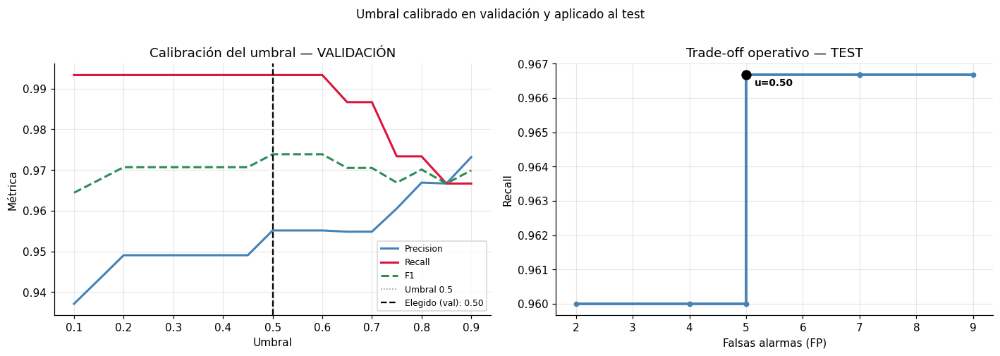

════════════════════════════════════════════════════════════════
UMBRAL ELEGIDO EN VALIDACIÓN: u = 0.50
════════════════════════════════════════════════════════════════
  En VALIDACIÓN -> F1=0.974  P=0.955  R=0.993
  En TEST       -> F1=0.967  P=0.967  R=0.967
  Test: 5 falsas alarmas de 143 videos pacíficos
  Test: 5 videos violentos no detectados


In [ ]:
# Calibración del umbral SOBRE VALIDACIÓN; luego se aplica FIJO al test (sin fuga)
umbrales = np.arange(0.10, 0.95, 0.05)

def metricas_en(y_t, y_s, u):
    yp = (y_s > u).astype(int)
    tp = int(((yp==1)&(y_t==1)).sum()); fp = int(((yp==1)&(y_t==0)).sum())
    fn = int(((yp==0)&(y_t==1)).sum()); tn = int(((yp==0)&(y_t==0)).sum())
    prec = tp/(tp+fp+1e-10); rec = tp/(tp+fn+1e-10)
    f1 = 2*prec*rec/(prec+rec+1e-10); acc = (tp+tn)/len(y_t)
    return dict(umbral=u, precision=prec, recall=rec, f1=f1, accuracy=acc,
                tp=tp, fp=fp, fn=fn, tn=tn)

# 1) Barrido en VALIDACIÓN -> se elige el umbral (máximo F1)
val_sweep  = pd.DataFrame([metricas_en(y_val_true, y_val_scores, u) for u in umbrales])
best_idx   = val_sweep['f1'].idxmax()
umbral_opt = float(val_sweep.loc[best_idx, 'umbral'])

# 2) Se aplica ese umbral FIJO al TEST (mismo grid -> mismo índice)
test_sweep = pd.DataFrame([metricas_en(y_true, y_scores, u) for u in umbrales])
r_val  = val_sweep.loc[best_idx]
r_test = test_sweep.loc[best_idx]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Izquierda: calibración en VALIDACIÓN
axes[0].plot(val_sweep['umbral'], val_sweep['precision'], 'steelblue', lw=2, label='Precision')
axes[0].plot(val_sweep['umbral'], val_sweep['recall'],    'crimson',   lw=2, label='Recall')
axes[0].plot(val_sweep['umbral'], val_sweep['f1'],        'seagreen',  lw=2, ls='--', label='F1')
axes[0].axvline(0.5, color='gray', lw=1, ls=':', label='Umbral 0.5')
axes[0].axvline(umbral_opt, color='black', lw=1.5, ls='--', label=f'Elegido (val): {umbral_opt:.2f}')
axes[0].set_xlabel("Umbral"); axes[0].set_ylabel("Métrica")
axes[0].set_title("Calibración del umbral — VALIDACIÓN")
axes[0].legend(fontsize=8); axes[0].grid(True, alpha=0.3)

# Derecha: trade-off operativo en TEST, con el punto de operación marcado
axes[1].plot(test_sweep['fp'], test_sweep['recall'], 'steelblue', lw=2.5, marker='o', ms=4)
axes[1].scatter([r_test['fp']], [r_test['recall']], color='black', zorder=5, s=70)
axes[1].annotate(f"u={umbral_opt:.2f}", (r_test['fp'], r_test['recall']),
                 textcoords='offset points', xytext=(8, -10), fontsize=9, weight='bold')
axes[1].set_xlabel("Falsas alarmas (FP)"); axes[1].set_ylabel("Recall")
axes[1].set_title("Trade-off operativo — TEST")
axes[1].grid(True, alpha=0.3)

plt.suptitle("Umbral calibrado en validación y aplicado al test", fontsize=11, y=1.01)
plt.tight_layout(); plt.show()

print("═"*64)
print(f"UMBRAL ELEGIDO EN VALIDACIÓN: u = {umbral_opt:.2f}")
print("═"*64)
print(f"  En VALIDACIÓN -> F1={r_val['f1']:.3f}  P={r_val['precision']:.3f}  R={r_val['recall']:.3f}")
print(f"  En TEST       -> F1={r_test['f1']:.3f}  P={r_test['precision']:.3f}  R={r_test['recall']:.3f}")
print(f"  Test: {int(r_test['fp'])} falsas alarmas de {(y_true==0).sum()} videos pacíficos")
print(f"  Test: {int(r_test['fn'])} videos violentos no detectados")


---



### 9. Análisis de errores — videos mal clasificados

Total de errores: 10 / 293
  Falsos positivos (NoViolencia → Violencia): 5
  Falsos negativos (Violencia → NoViolencia): 5



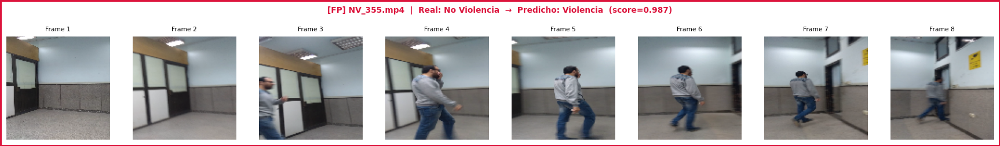

────────────────────────────────────────────────────────────────────────────────


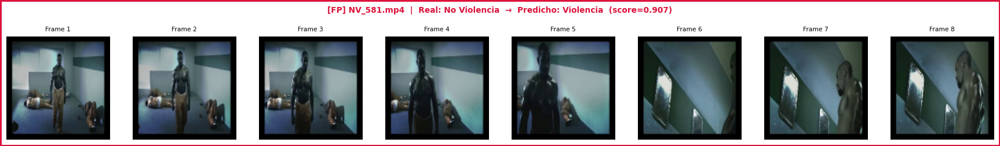

────────────────────────────────────────────────────────────────────────────────


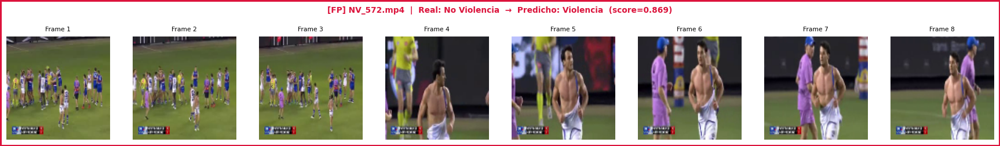

────────────────────────────────────────────────────────────────────────────────


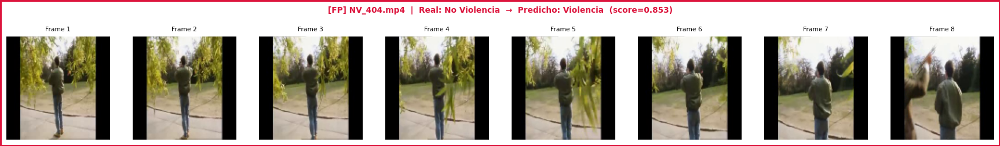

────────────────────────────────────────────────────────────────────────────────


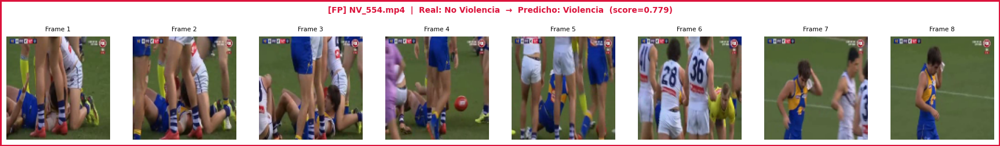

────────────────────────────────────────────────────────────────────────────────


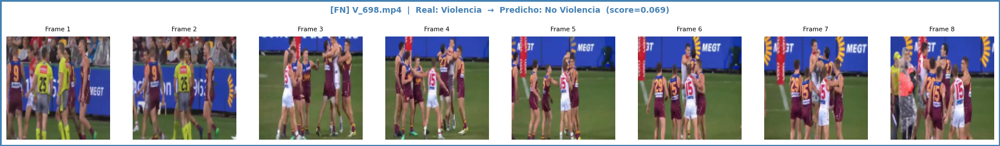

────────────────────────────────────────────────────────────────────────────────


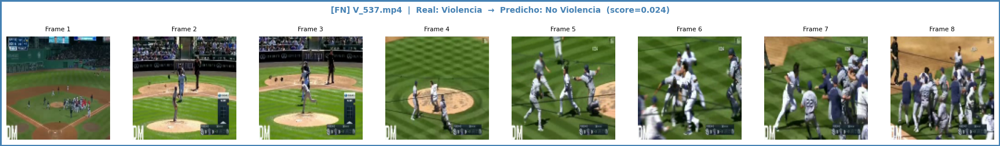

────────────────────────────────────────────────────────────────────────────────


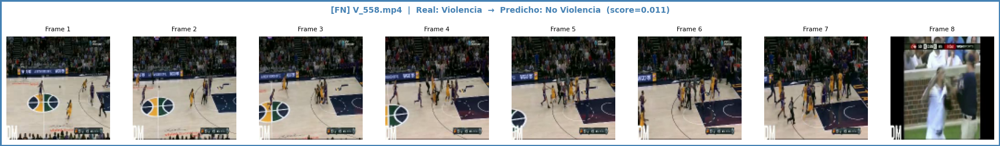

────────────────────────────────────────────────────────────────────────────────


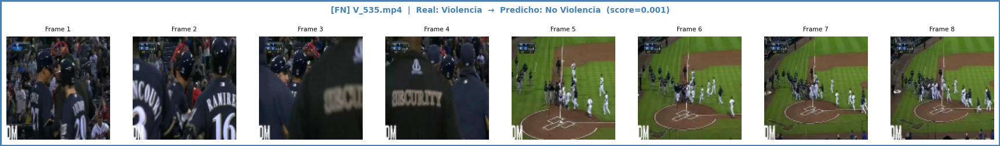

────────────────────────────────────────────────────────────────────────────────


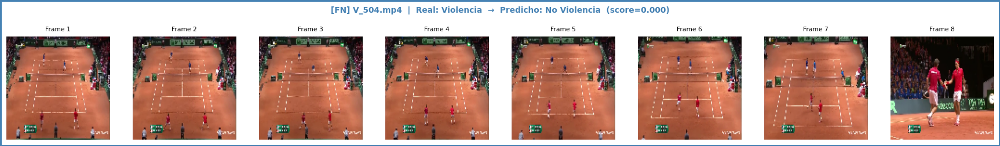

────────────────────────────────────────────────────────────────────────────────


In [ ]:
# Videos mal clasificados en el test set
# splits['test'] fue construido con shuffle=False, así que el orden coincide con y_true / y_scores

test_paths = [path for _, path in splits['test']]

# Armar DataFrame con todos los resultados del test
df_test_results = pd.DataFrame({
    'path':      test_paths,
    'y_true':    y_true,
    'y_pred':    y_pred,
    'score':     y_scores,
    'label_true': [LABELS[l] for l in y_true],
    'label_pred': [LABELS[p] for p in y_pred],
})

df_errors = df_test_results[df_test_results['y_true'] != df_test_results['y_pred']].copy()
df_errors = df_errors.sort_values('score', ascending=False).reset_index(drop=True)

print(f"Total de errores: {len(df_errors)} / {len(df_test_results)}")
print(f"  Falsos positivos (NoViolencia → Violencia): {((df_errors.y_true==0) & (df_errors.y_pred==1)).sum()}")
print(f"  Falsos negativos (Violencia → NoViolencia): {((df_errors.y_true==1) & (df_errors.y_pred==0)).sum()}")
print()

# Mostrar frames de los videos mal clasificados
N_COLS = 8
for i, row in df_errors.iterrows():
    frames = get_sample_frames(row['path'], n_frames=N_COLS, size=(112, 112))
    fig, axes = plt.subplots(1, N_COLS, figsize=(16, 2.2))
    color = 'crimson' if row['y_pred'] == 1 else 'steelblue'
    fig.patch.set_edgecolor(color)
    fig.patch.set_linewidth(3)
    for j, frame in enumerate(frames):
        axes[j].imshow(frame)
        axes[j].axis('off')
        if j == 0:
            axes[j].set_title(f"Frame {j+1}", fontsize=7)
        else:
            axes[j].set_title(f"Frame {j+1}", fontsize=7)
    tipo = "FP" if row['y_true'] == 0 else "FN"
    fig.suptitle(
        f"[{tipo}] {Path(row['path']).name}  |  "
        f"Real: {row['label_true']}  →  Predicho: {row['label_pred']}  (score={row['score']:.3f})",
        fontsize=9, weight='bold', color=color, y=1.02
    )
    plt.tight_layout()
    plt.show()

    display(play_video(row['path'], width=400))
    print("─" * 80)